# SeismicDataset. Подготовка сейсмического датасета #

## 1.2. Влияние сглаживания на волновое поле ##

Как меняется сейсмограмма, если заменить ступенчатый контакт материалов гладкой кривой? В пилоте ECVB12404 можно отдельно оценить влияние геометрии, порядка решения и шага по времени. ECVB00065 проверяет, удаётся ли сохранить короткие контакты и стыки нескольких сред. Ниже приведены постановка и рисунки из [презентации 5 ноября](presentation/dev_1_2_seismic_dataset_sem_review_20261105.pptx).

In [1]:
from zipfile import ZipFile

from IPython.display import Image, Markdown, display

from scripts.project_paths import PROJECT_ROOT as ROOT
from scripts.reporting import comparison_summary, mapping, pair, read_json, sequence

data = ROOT / "data/dev_1_2_smoothing"
slides = ROOT / "presentation/dev_1_2_seismic_dataset_sem_review_20261105.pptx"

In [2]:
def slide_figure(image_number: int, width: int = 850) -> None:
    with ZipFile(slides) as archive:
        png = archive.read(f"ppt/media/image{image_number}.png")
    display(Image(data=png, width=width))

In [3]:
def percent(fraction: float, digits: int = 2) -> str:
    return f"{100 * fraction:.{digits}f}".replace(".", ",")

### Постановка двух опытов ###

Исходная модель занимает квадрат 700 × 700 м. Каждая из 70 × 70 ячеек хранит пару скоростей Vp и Vs. В обеих сериях по 30 000 моделей. В EFVB встречается от 3 до 10 материалов на модель, в ECVB от 3 до 12. На исходных картах красный канал кодирует Vp, зелёный — Vs, синий равен нулю. Общие шкалы составляют 1500–4500 м/с для Vp и 615,71–2999,37 м/с для Vs. Разбивка по сериям и обзор карт приведены в [главе 1.1](dev_1_1_dataset_preprocessing.ipynb).

В обоих опытах решалась задача плоской деформации при плотности 1000 кг/м³. Верхняя поверхность свободна, на боковых границах и дне заданы поглощающие условия ABC. В исходном письме Василия предлагалось задавать вертикальное перемещение последовательно в пяти положениях x = 0, 175, 350, 525 и 700 м. Крайние положения приходятся на стык свободной грани с ABC и требуют отдельной проверки.

В пилотах действовала одна вертикальная сила в центре верха. Её равнодействующая направлена вниз, амплитуда составляет 1 Н на единицу толщины. Нагрузка распределена по отрезку [345, 355] м как усечённая гауссиана с σ = 5/3 м. Временная форма — импульс Рикера 15 Гц с центром 0,1 с. Это граничная тяга, интегрированная по функциям формы. Кинематические источники (заданные перемещение, скорость или ускорение), узловая сила, граничное и объёмное давление задают другие способы возбуждения. Для сравнения сеток нагрузка в физических координатах фиксирована.

На верхней грани 71 приёмник в точках x = 0, 10, …, 700 м записывал перемещения Ux и Uy через 1 мс от 0 до 2 с включительно. Поля в объёме сравнивались в одних и тех же физических точках — центрах 70 × 70 исходных ячеек.

### От растровой ступеньки к общей границе ###

Сначала выделяем связные области материала и находим, какие из них соприкасаются. Между соседями строим одну общую кривую и закрепляем её концы в точках стыка. Тогда обе области получают одно и то же ребро. Фильтрация самих меток до построения границ способна стереть узкую область или короткий контакт. На рисунке из презентации сопоставлены исходные карты и варианты обработки.

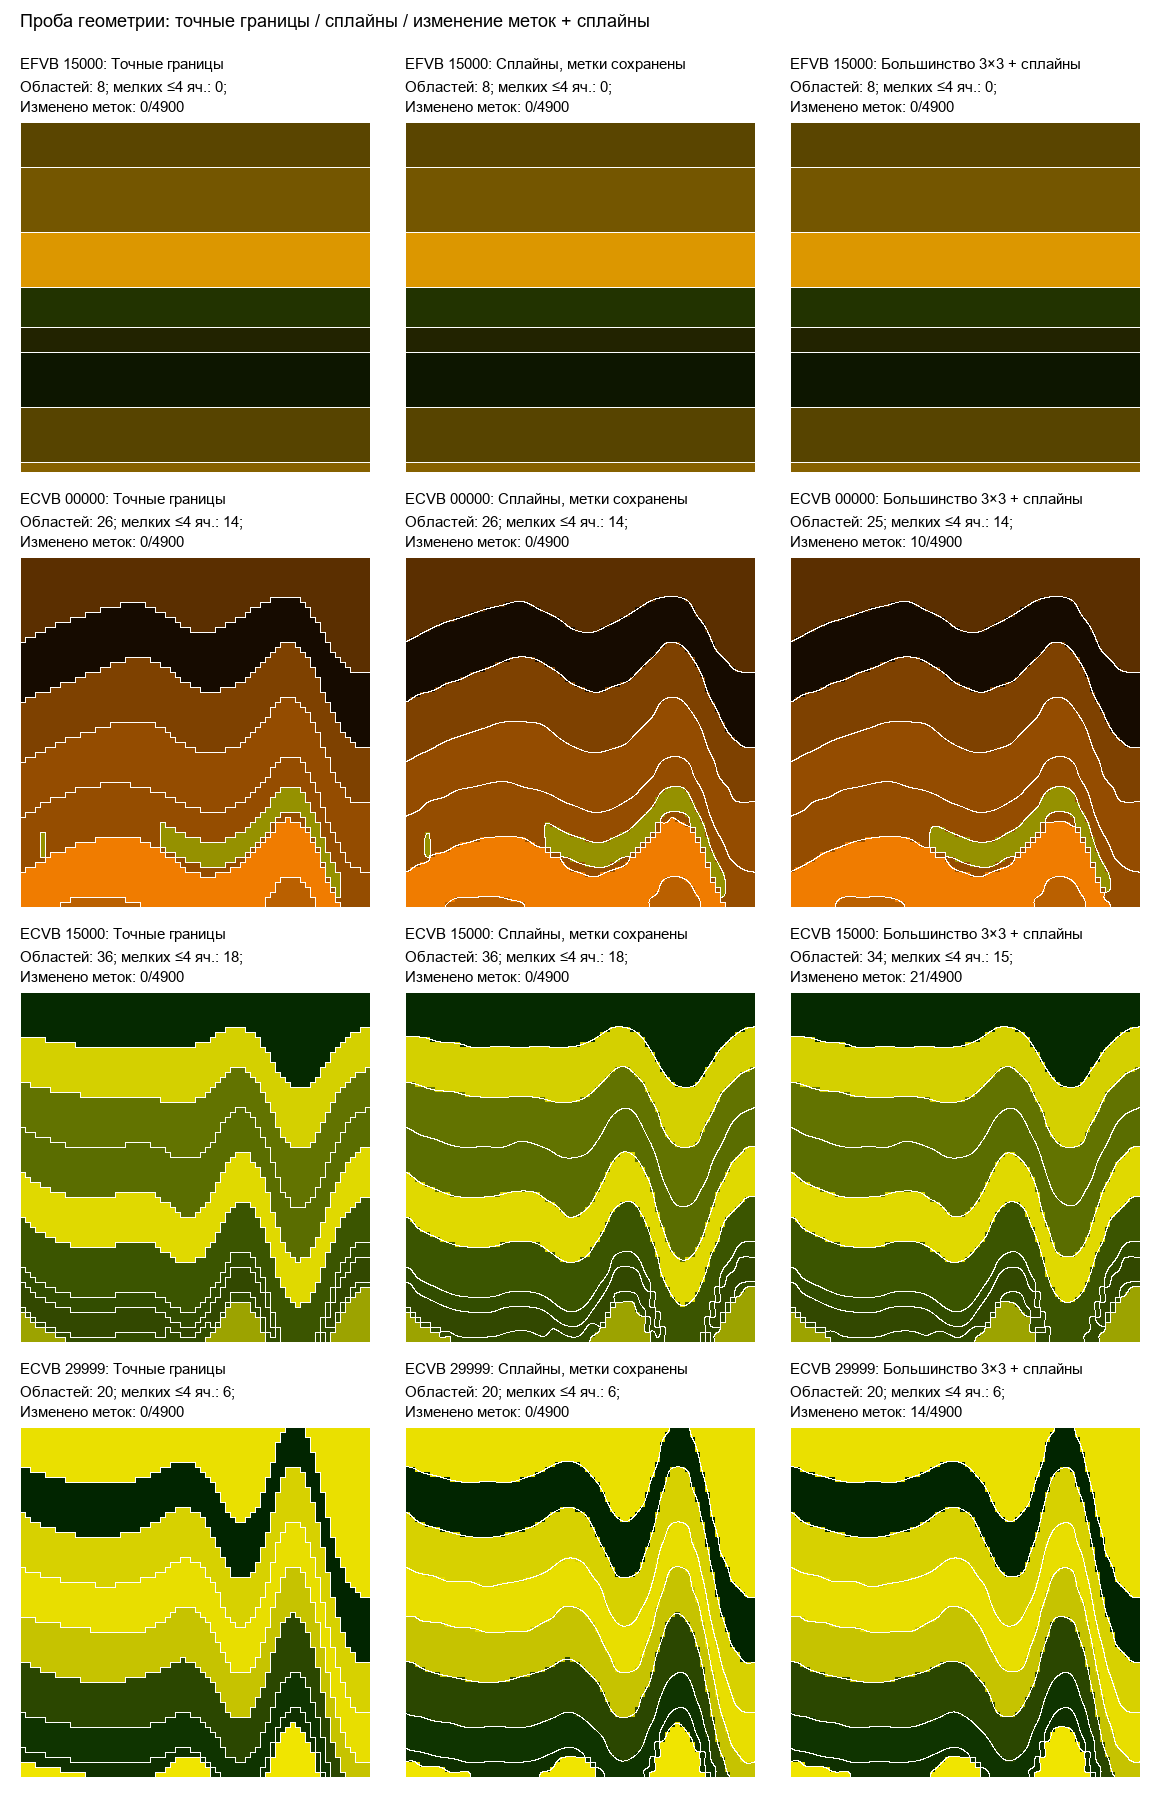

In [4]:
slide_figure(4, width=650)

**ECVB12404.** У модели четыре сквозных слоя с одинаковой последовательностью во всех столбцах и минимальной толщиной 80 м. Верхний из трёх интерфейсов горизонтален. Через два изогнутых контакта меняется только Vs. Обе сетки содержат по 4900 четырёхугольников и имеют по 78 961 глобальному узлу при p4 и по 123 201 при p5. После сглаживания 0,685% площади переходит от одного материала к другому. Такая геометрия специально выбрана для контроля сходимости.

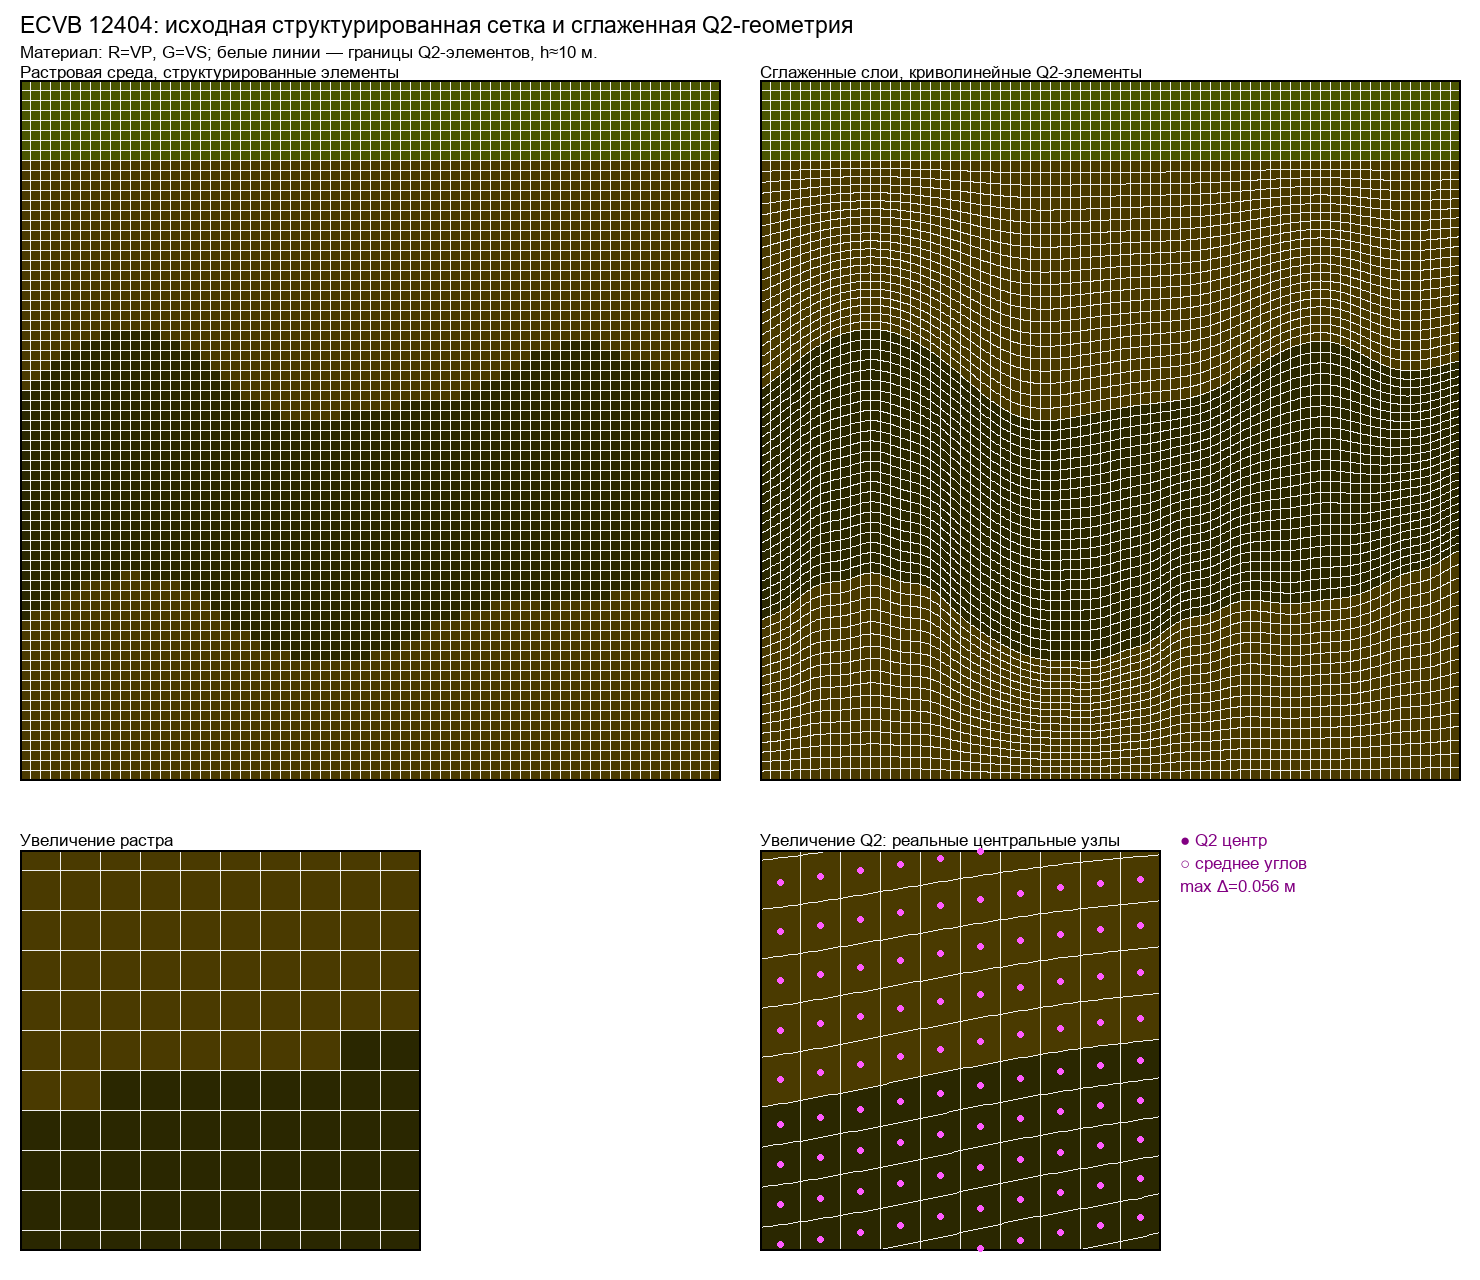

In [5]:
slide_figure(5)

**ECVB00065.** Пять материалов образуют восемь связных областей, два тройных стыка и один четырёхсторонний. Сохранились все восемь областей и контакт длиной всего 10 м. Границы описаны 24 кривыми, из них семь — кубические B-сплайны. В исходной сетке 4900 квадратов, в согласованной с границами сетке 6075 четырёхугольников и 97 669 глобальных узлов при p4. Положительность якобиана проверена на всей площади каждого элемента. По классификации с шагом 1 м принадлежность материала изменилась примерно на 1,04% площади.

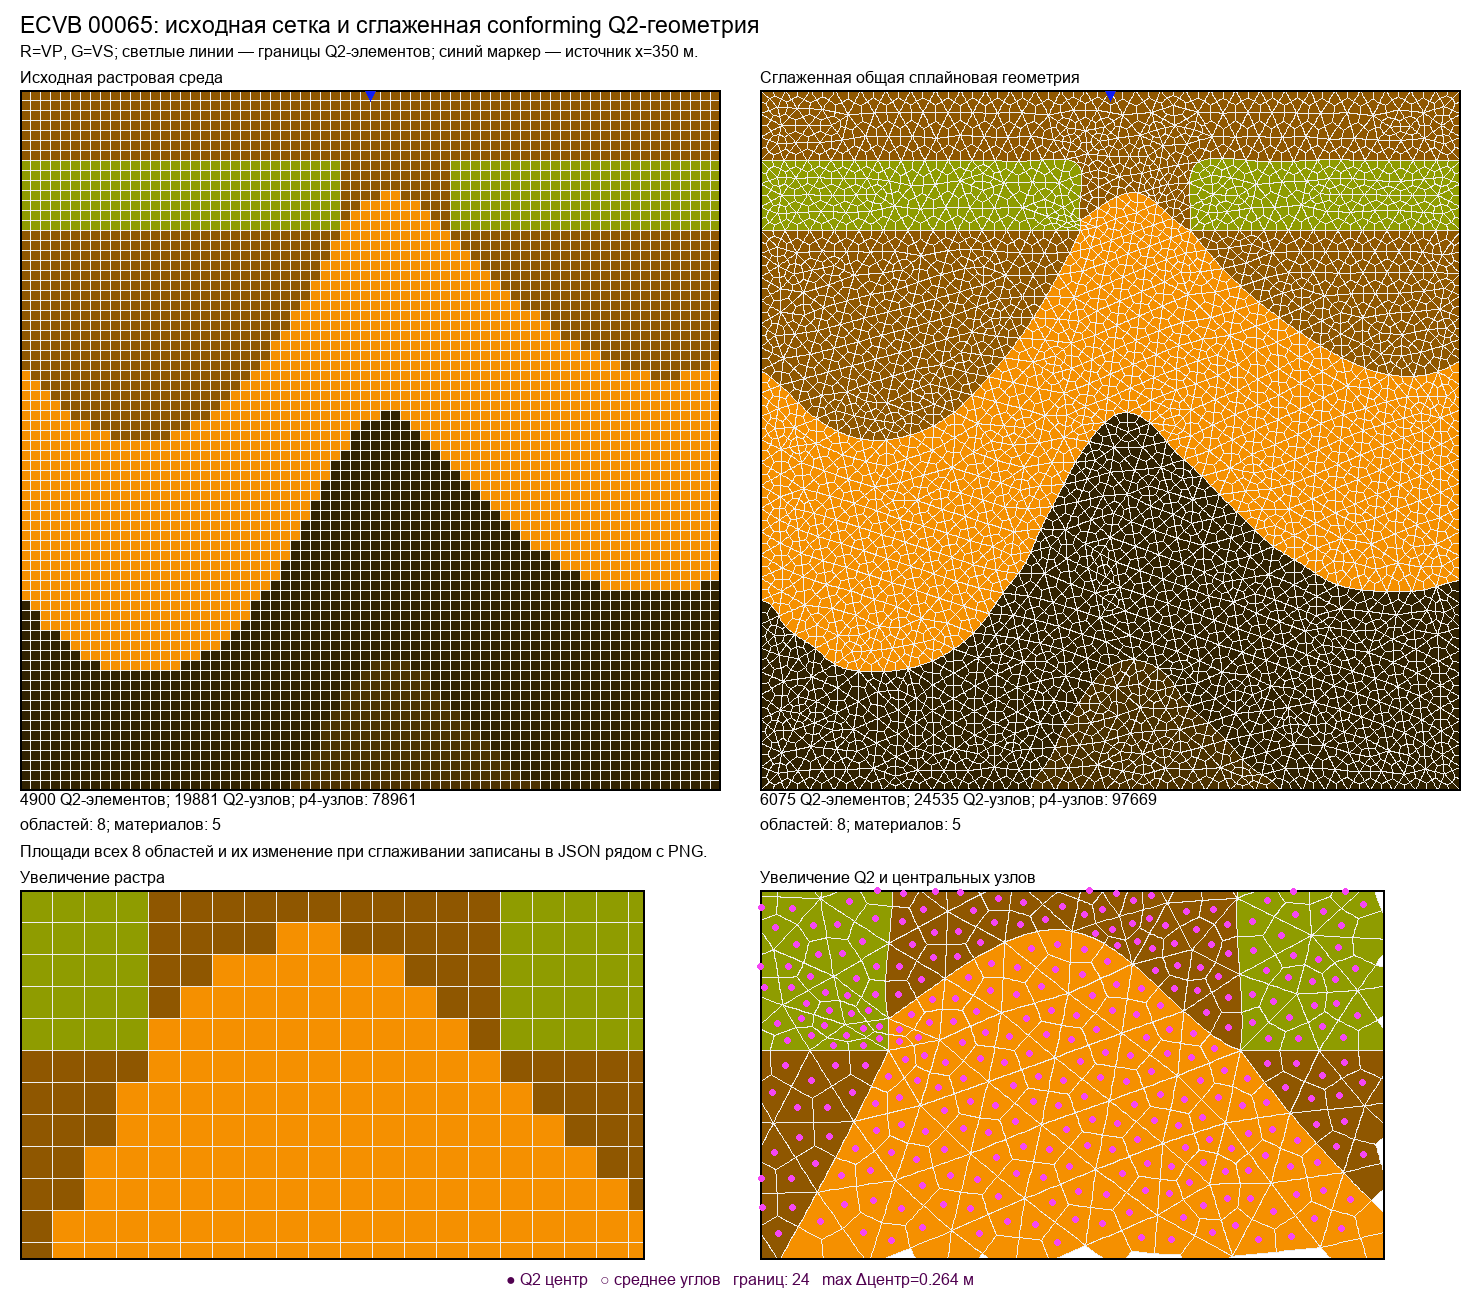

In [6]:
slide_figure(6)

### Геометрический порядок и разрешение волны ###

В этих опытах геометрию элемента задаёт фиксированная девятиузловая карта Q2. Порядок p определяет интерполяцию перемещений на этой карте. При p4 в элементе 5 × 5 узлов Гаусса — Лобатто — Лежандра (GLL), при p5 их 6 × 6. Для сравнения, разбиение квадрата на 4 × 4 элемента p1 даёт те же 25 узлов на блок, что и p4, но другое пространство функций. Внутри каждого элемента Vp, Vs и плотность постоянны и определяются меткой области.

При частоте 15 Гц минимальные по датасету длины волн составляют около 41 м для S-волны и 100 м для P-волны. При размере элемента 10 м оценка числа интервалов на длину волны даёт для p3, p4, p5 соответственно 12, 16, 21 для S-волны и 30, 40, 50 для P-волны. При 30 Гц все оценки вдвое меньше. Это ориентир для выбора порядков в опыте: узлы GLL распределены неравномерно, а размер криволинейного элемента меняется по сетке.

$$
N_λ ≈ pλ/h.
$$

### Сейсмограммы и поле при 2 с ###

Для каждой компоненты берём норму разности по всем приёмникам и отсчётам выбранного окна W. Знаменатель — норма записи исходной растровой модели в том же окне. Для снимка поля суммируем по общим точкам в объёме в один момент времени.

$$
D_c(W)=\frac{\lVert U_{c,\mathrm{curved}}-U_{c,\mathrm{raster}}\rVert_{2,W}}{\lVert U_{c,\mathrm{raster}}\rVert_{2,W}},\qquad c\in\{x,y\}.
$$

У №12404 показана пара p5 с шагом 27,78 мкс, воспроизведённая в повторе на CUDA. У №00065 показана исходная пара p4 с шагом 13,89 мкс. Таблица читается по столбцам: каждая ячейка содержит проценты для Ux / Uy.

In [7]:
layered = comparison_summary(data / "pilot_cu/comparison/report.json", "12404, p5")
junctions = comparison_summary(data / "model65/comparison/report.json", "00065, p4")
rows = ["| Наблюдение | ECVB12404, p5 | ECVB00065, p4 |", "|---|---:|---:|"]
for observation, first, second in (
    ("Поверхность, 0–2 с", layered.full, junctions.full),
    ("Поверхность, 1–2 с", layered.late, junctions.late),
    ("Поле, t = 2 с", layered.final_field, junctions.final_field),
):
    rows.append(f"| {observation} | {percent(first[0])} / {percent(first[1])} | {percent(second[0])} / {percent(second[1])} |")
display(Markdown("\n".join(rows)))

| Наблюдение | ECVB12404, p5 | ECVB00065, p4 |
|---|---:|---:|
| Поверхность, 0–2 с | 0,84 / 0,51 | 2,23 / 1,37 |
| Поверхность, 1–2 с | 18,48 / 16,08 | 13,75 / 6,23 |
| Поле, t = 2 с | 13,95 / 14,55 | 26,07 / 22,02 |

**Полная поверхностная запись.** Первый рисунок относится к №12404, второй к №00065. Для каждой компоненты растровая и сглаженная среды показаны в общей цветовой шкале, разность — в своей. Сильные прямые вступления доминируют в норме полной записи и близки в обеих средах.

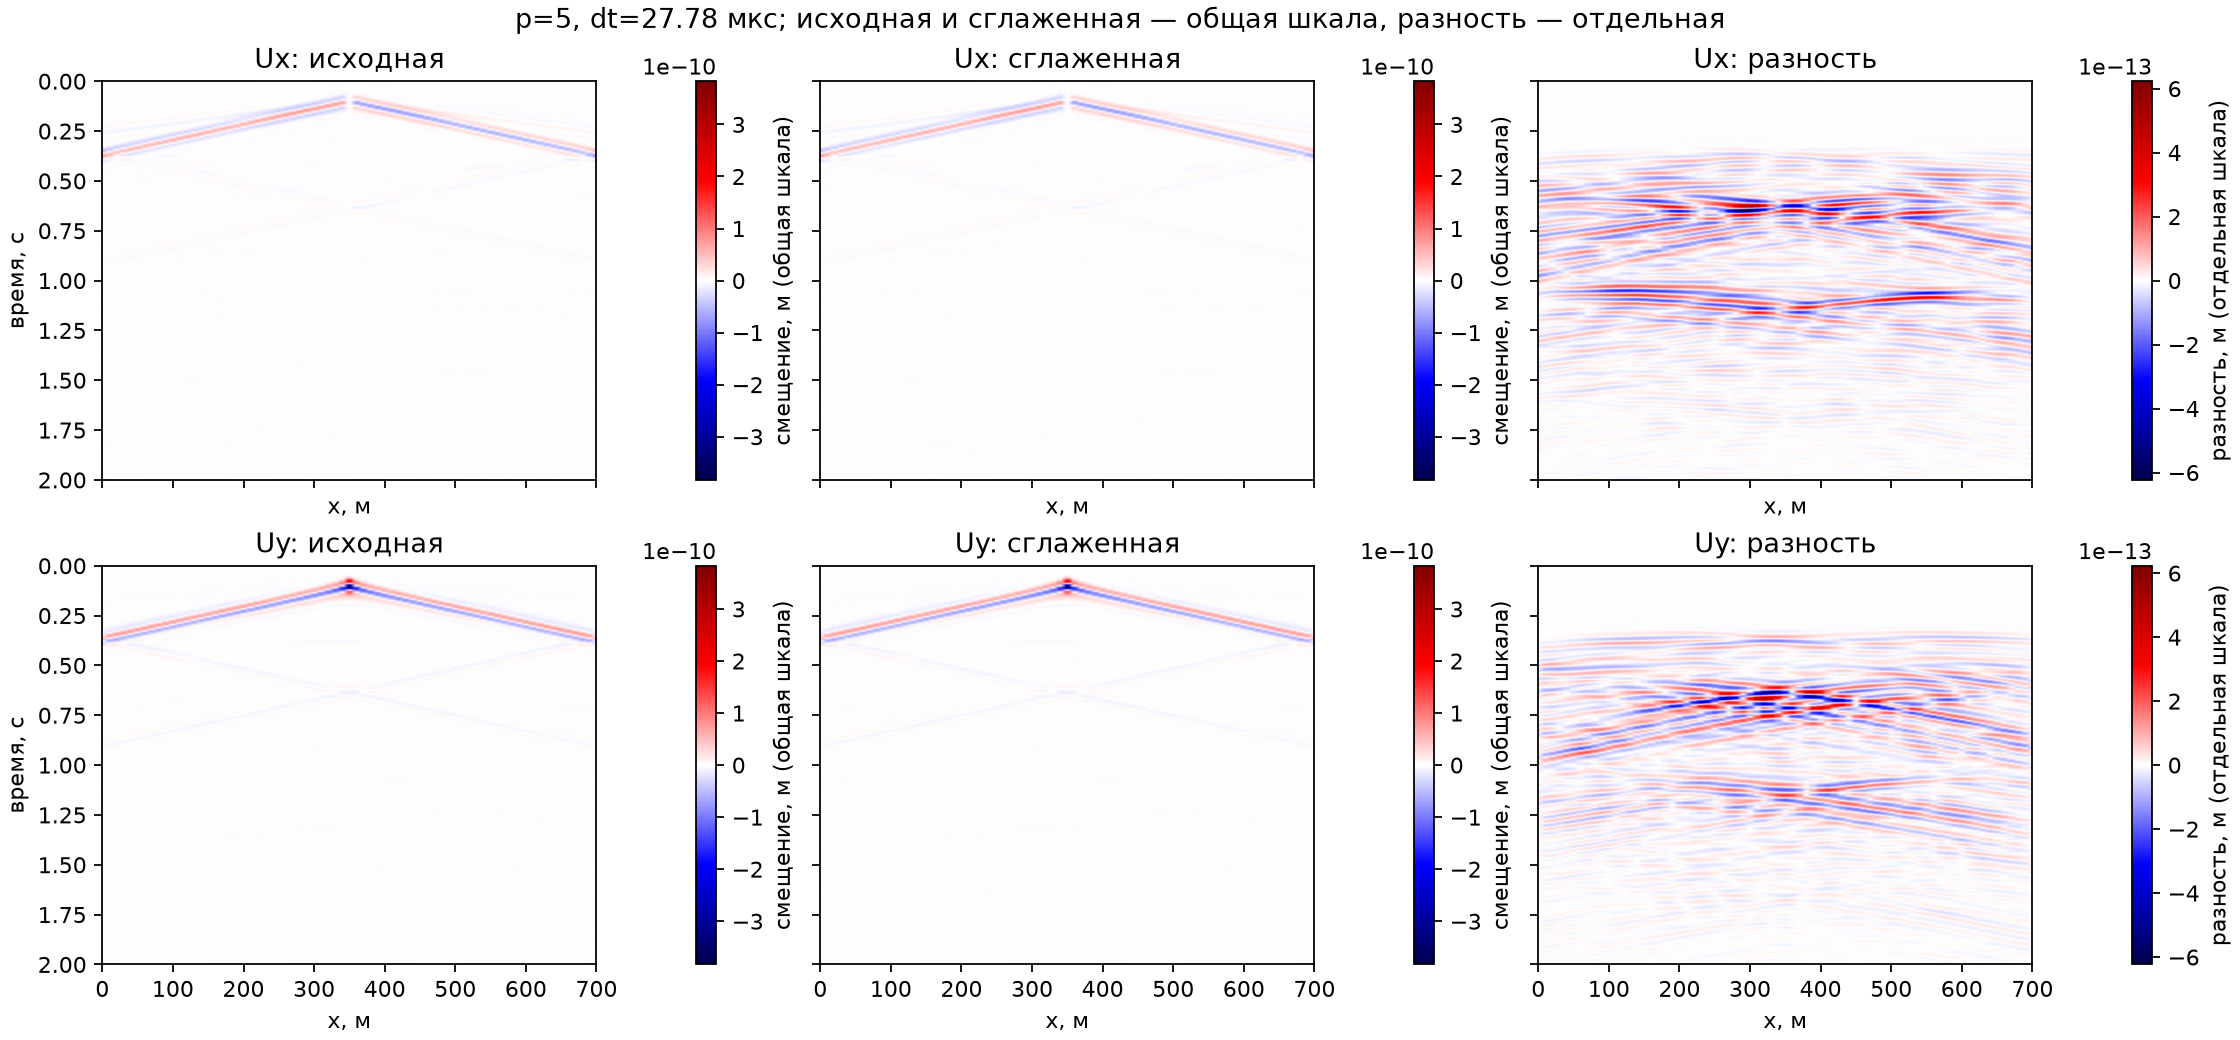

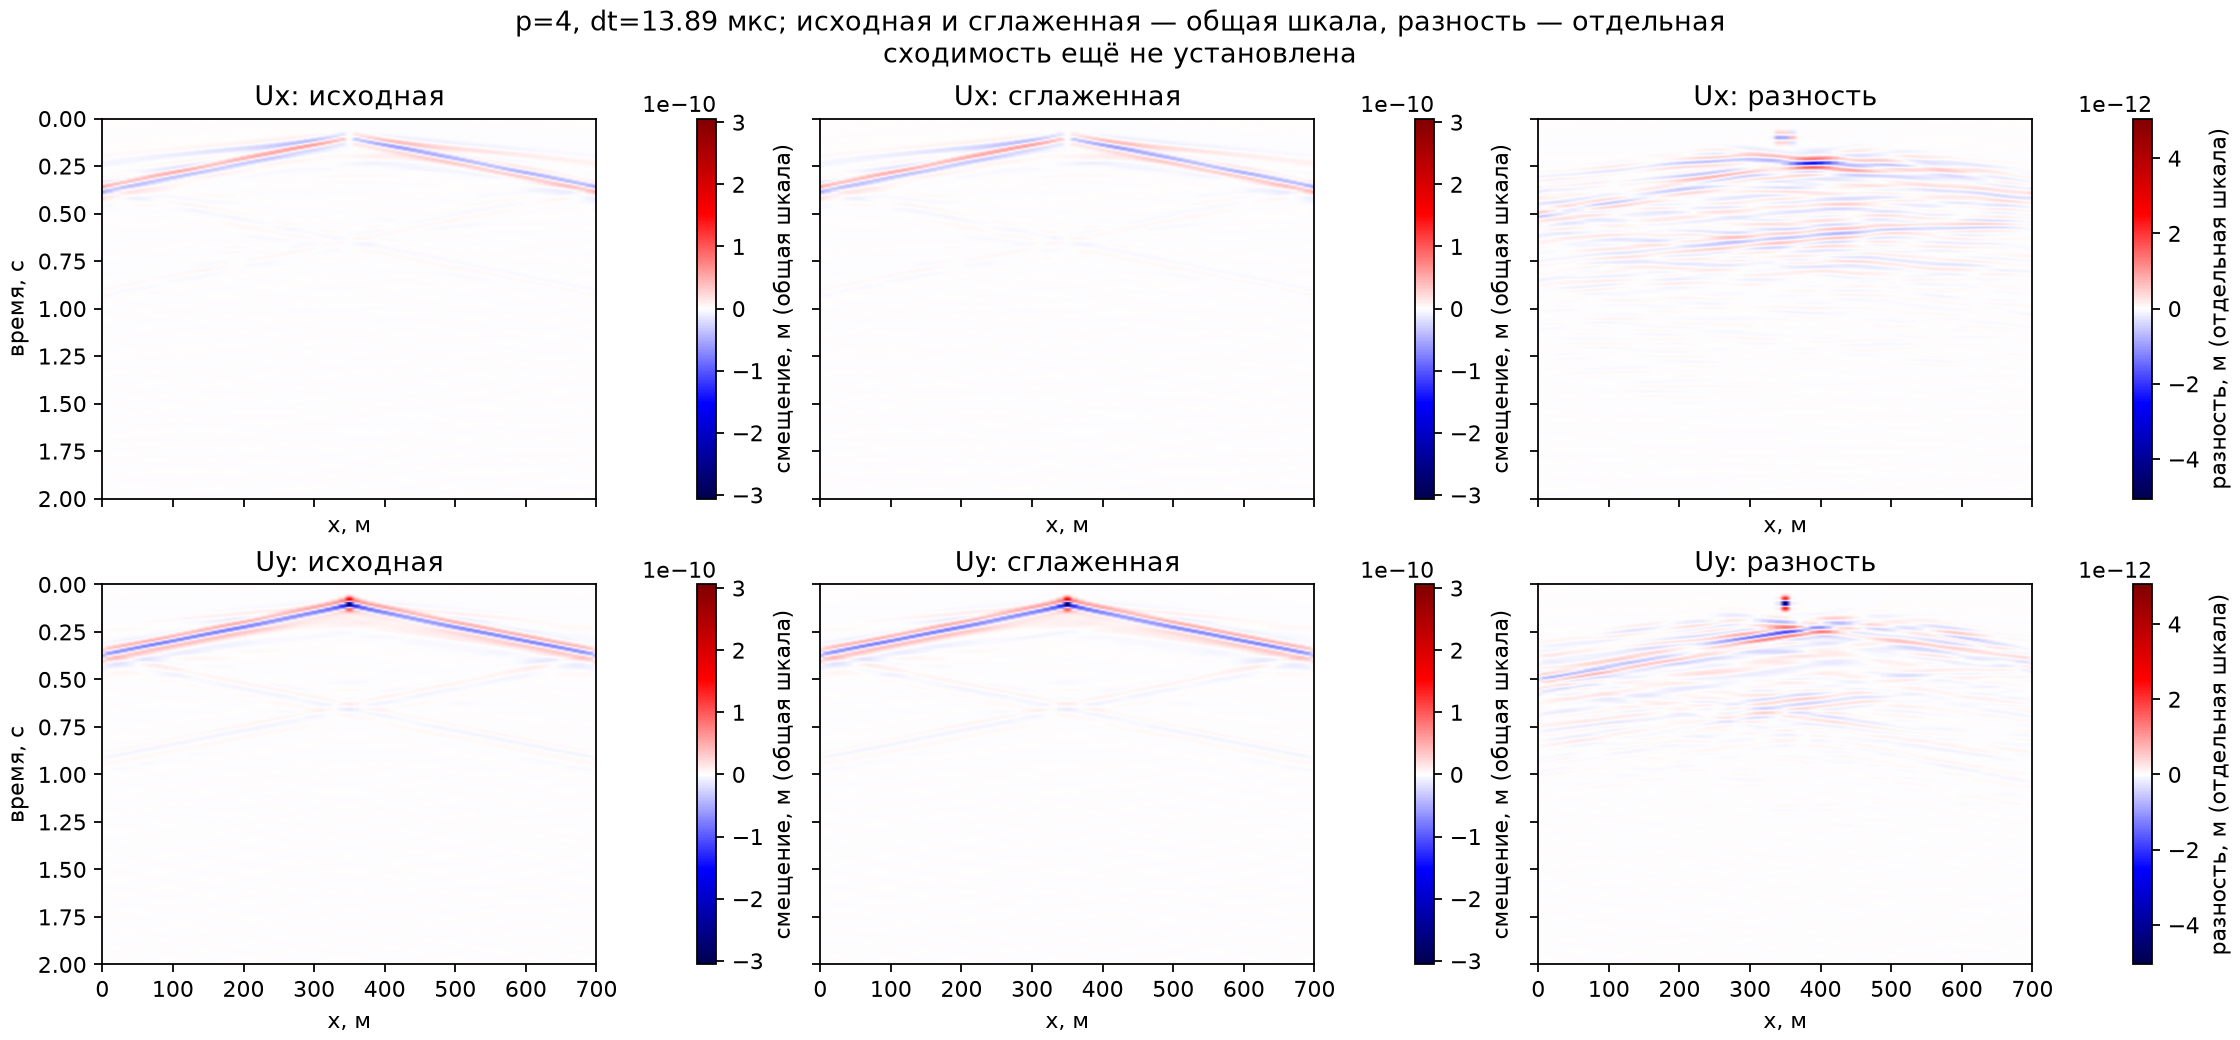

In [8]:
slide_figure(8)
slide_figure(9)

**Кода, 1–2 с.** Тот же порядок моделей. В слабой поздней записи видны изменения отражённых и рассеянных волн. У №00065 норма опорной коды составляет всего 1,85% полной нормы по Ux и 1,44% по Uy. Это объясняет, как заметное относительное изменение коды сочетается с близостью полных сейсмограмм.

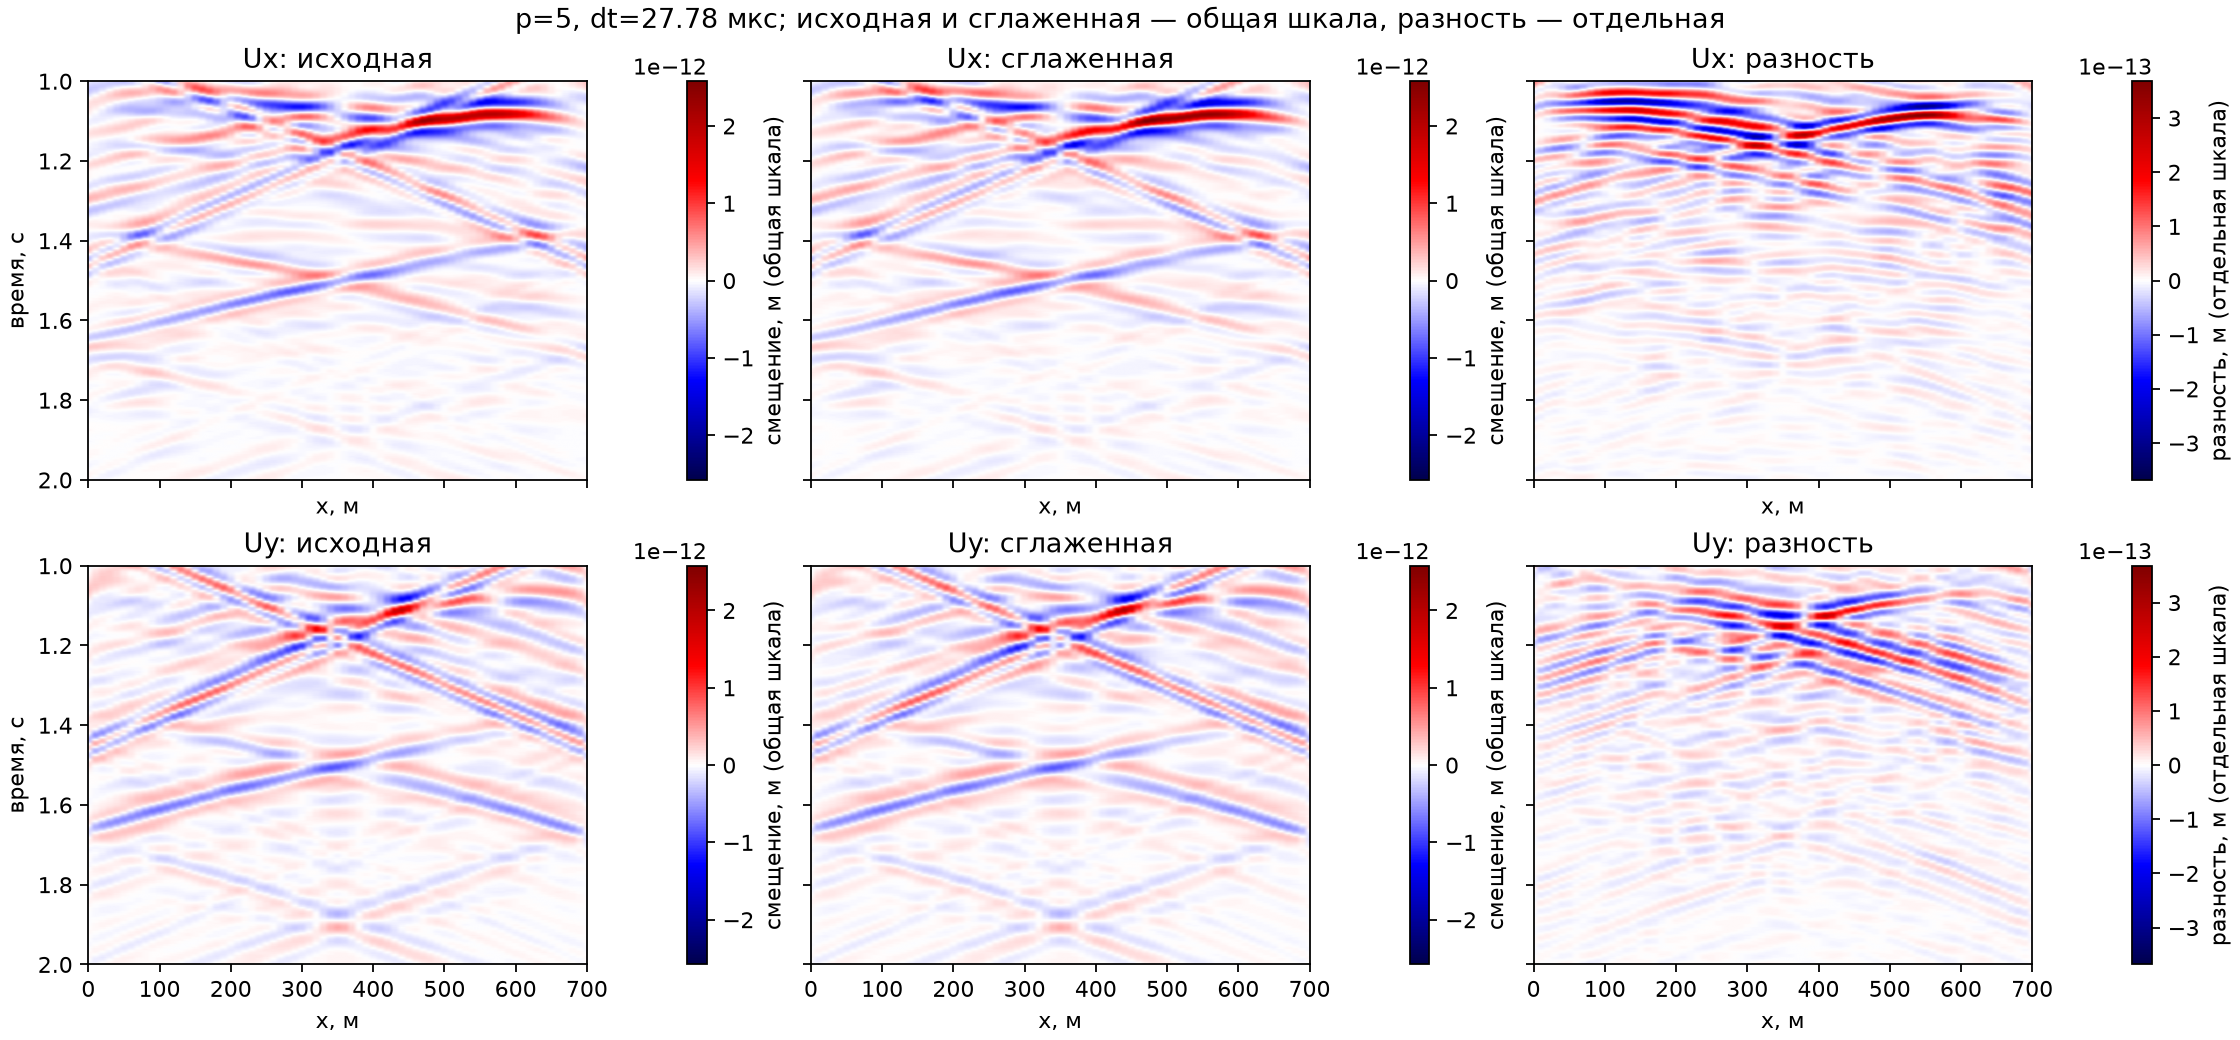

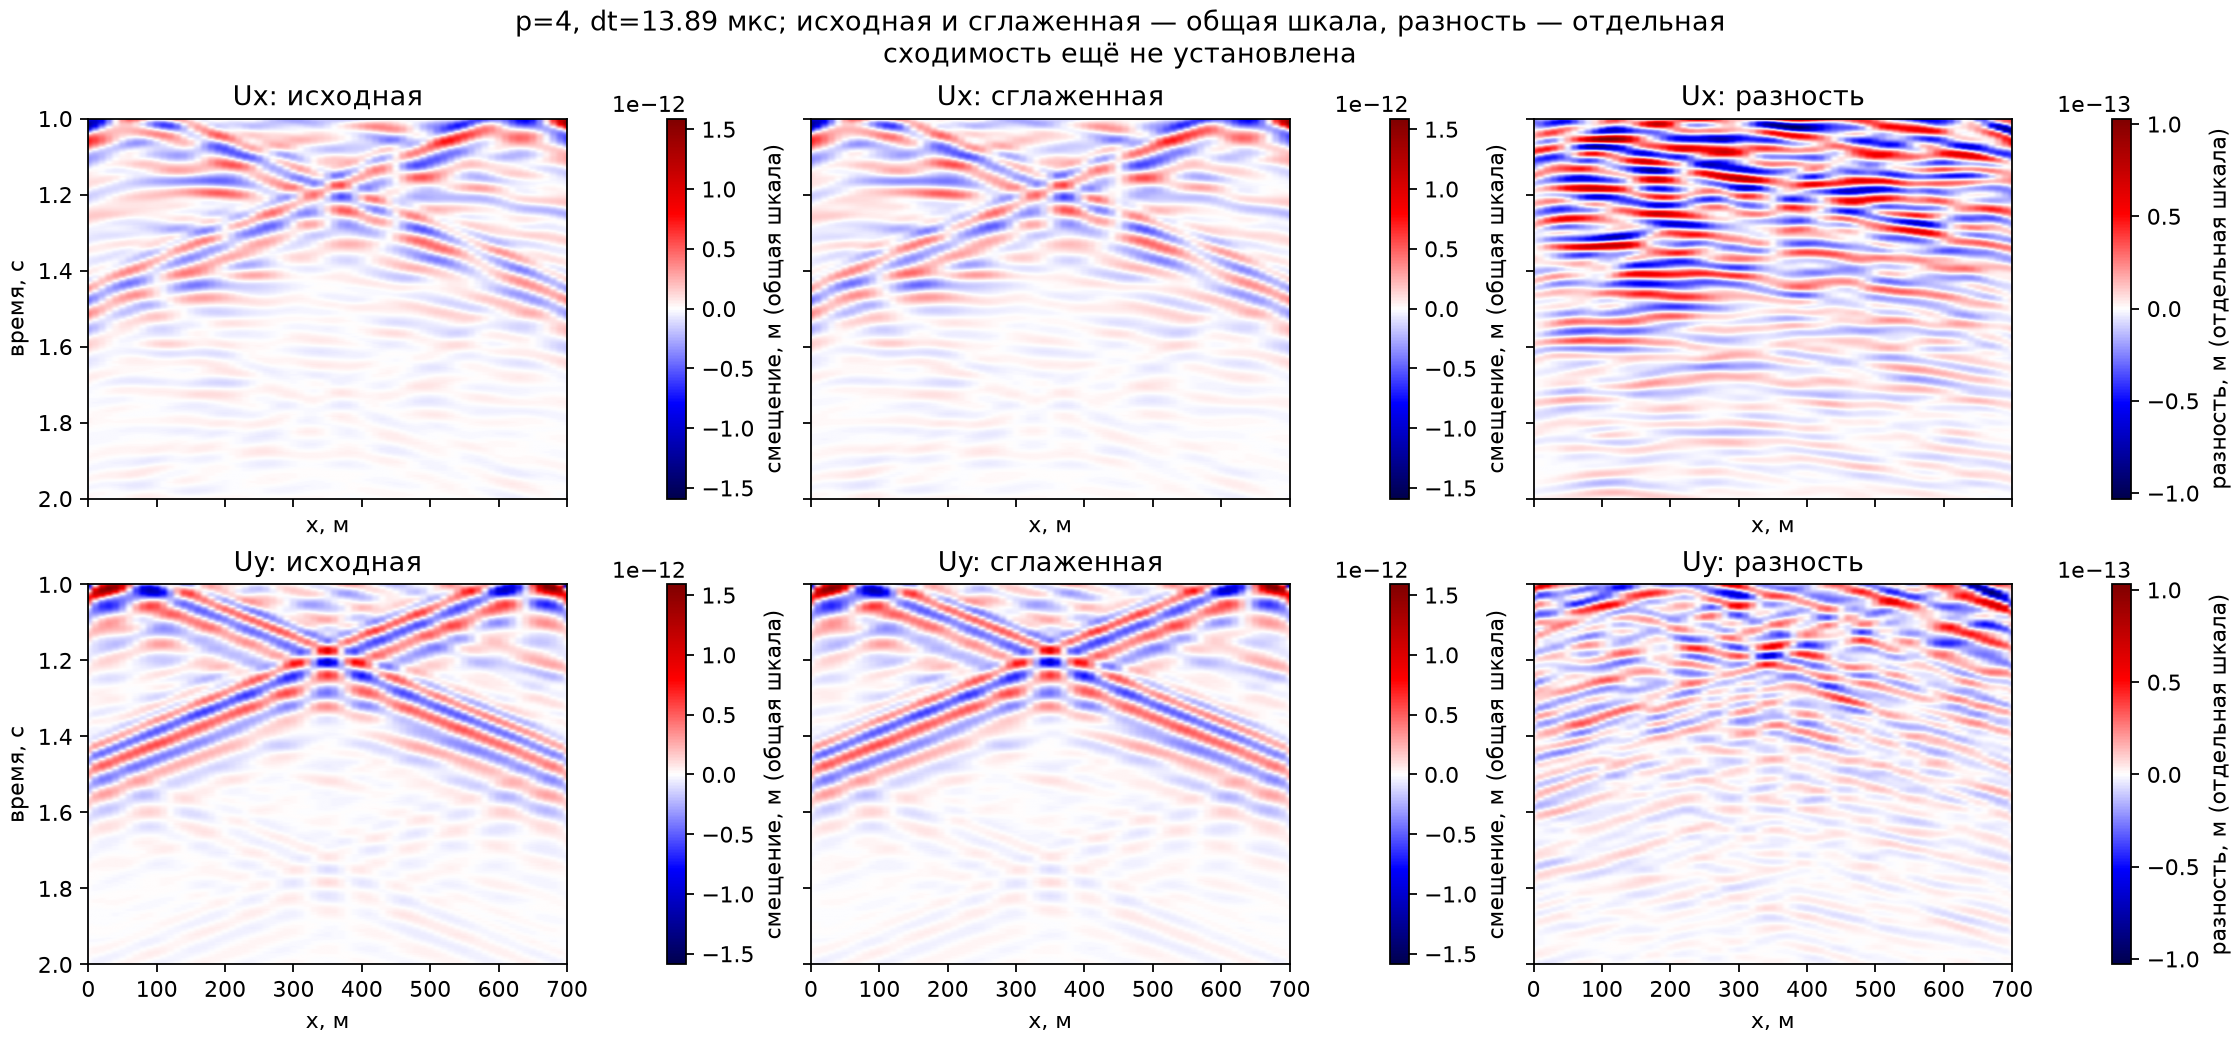

In [9]:
slide_figure(10)
slide_figure(11)

**Поля перемещений.** На каждом рисунке верхняя пара строк показывает поле при 1 с, нижняя — при 2 с. К концу расчёта амплитуды имеют порядок 10⁻¹³ м у №12404 и 10⁻¹⁴ м у №00065. На поверхности поздняя относительная разность больше у №12404, а в последнем снимке поля — у №00065. Поэтому величина эффекта зависит и от того, где регистрируется волна.

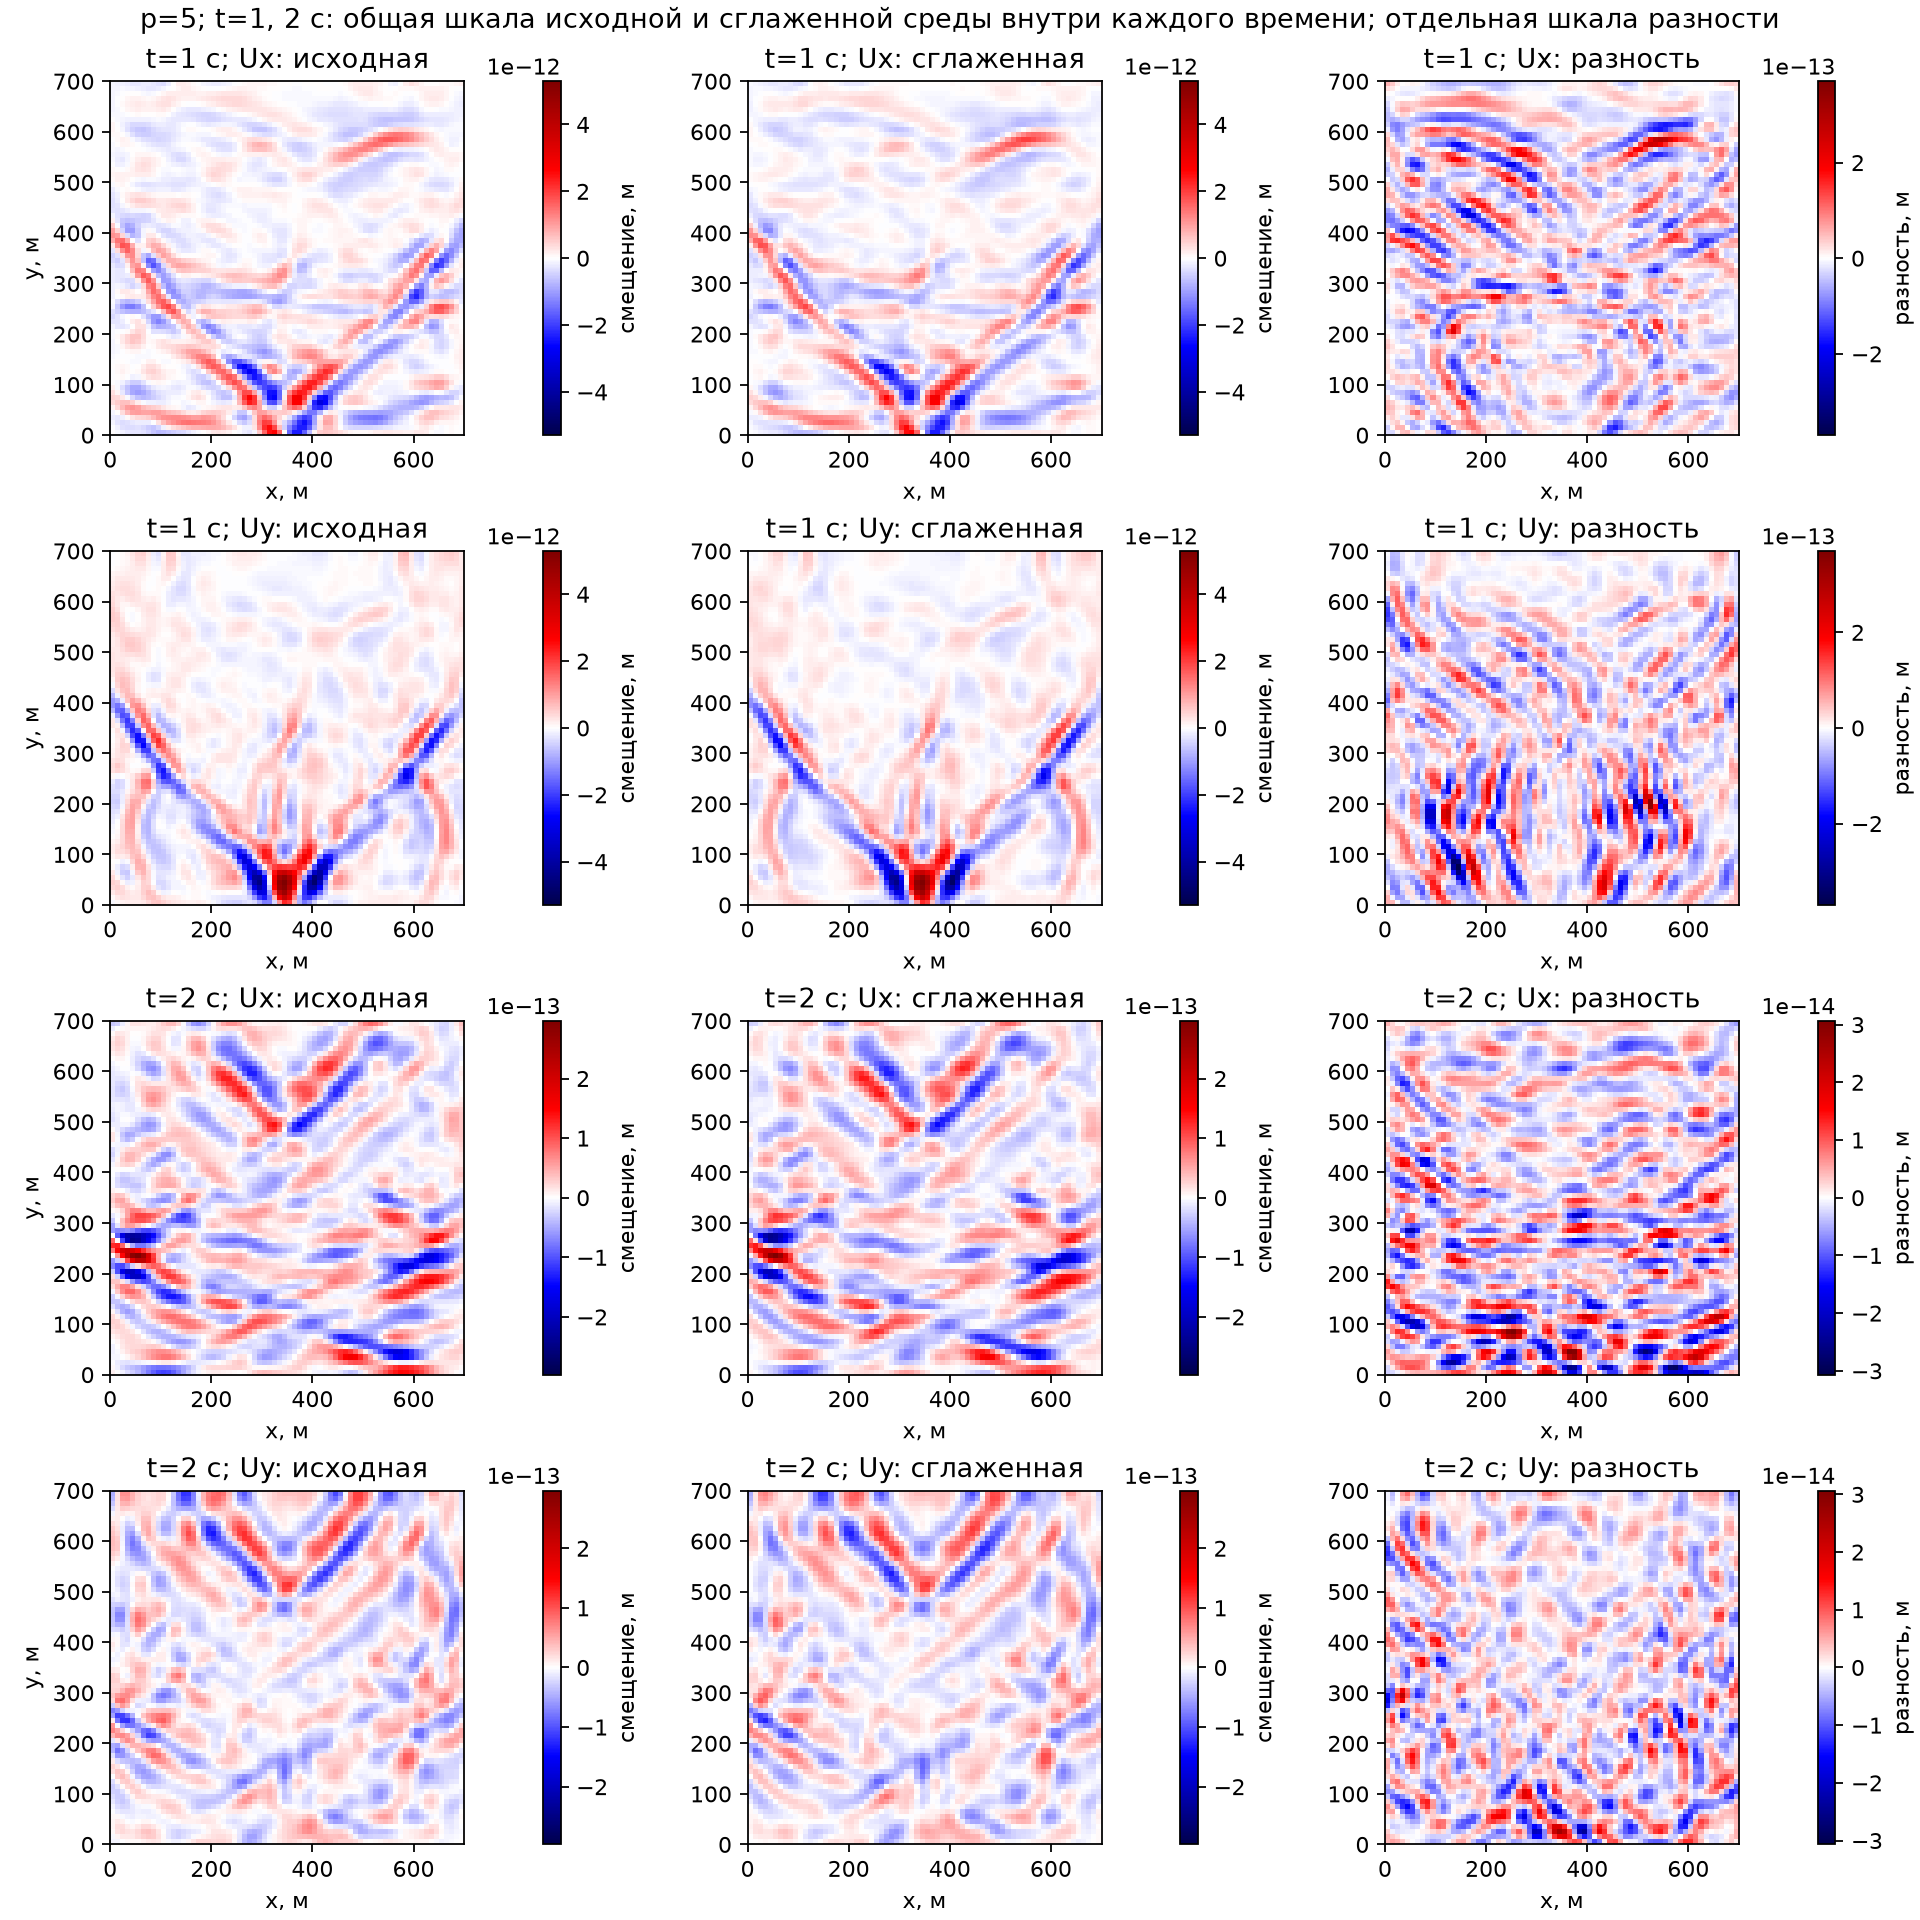

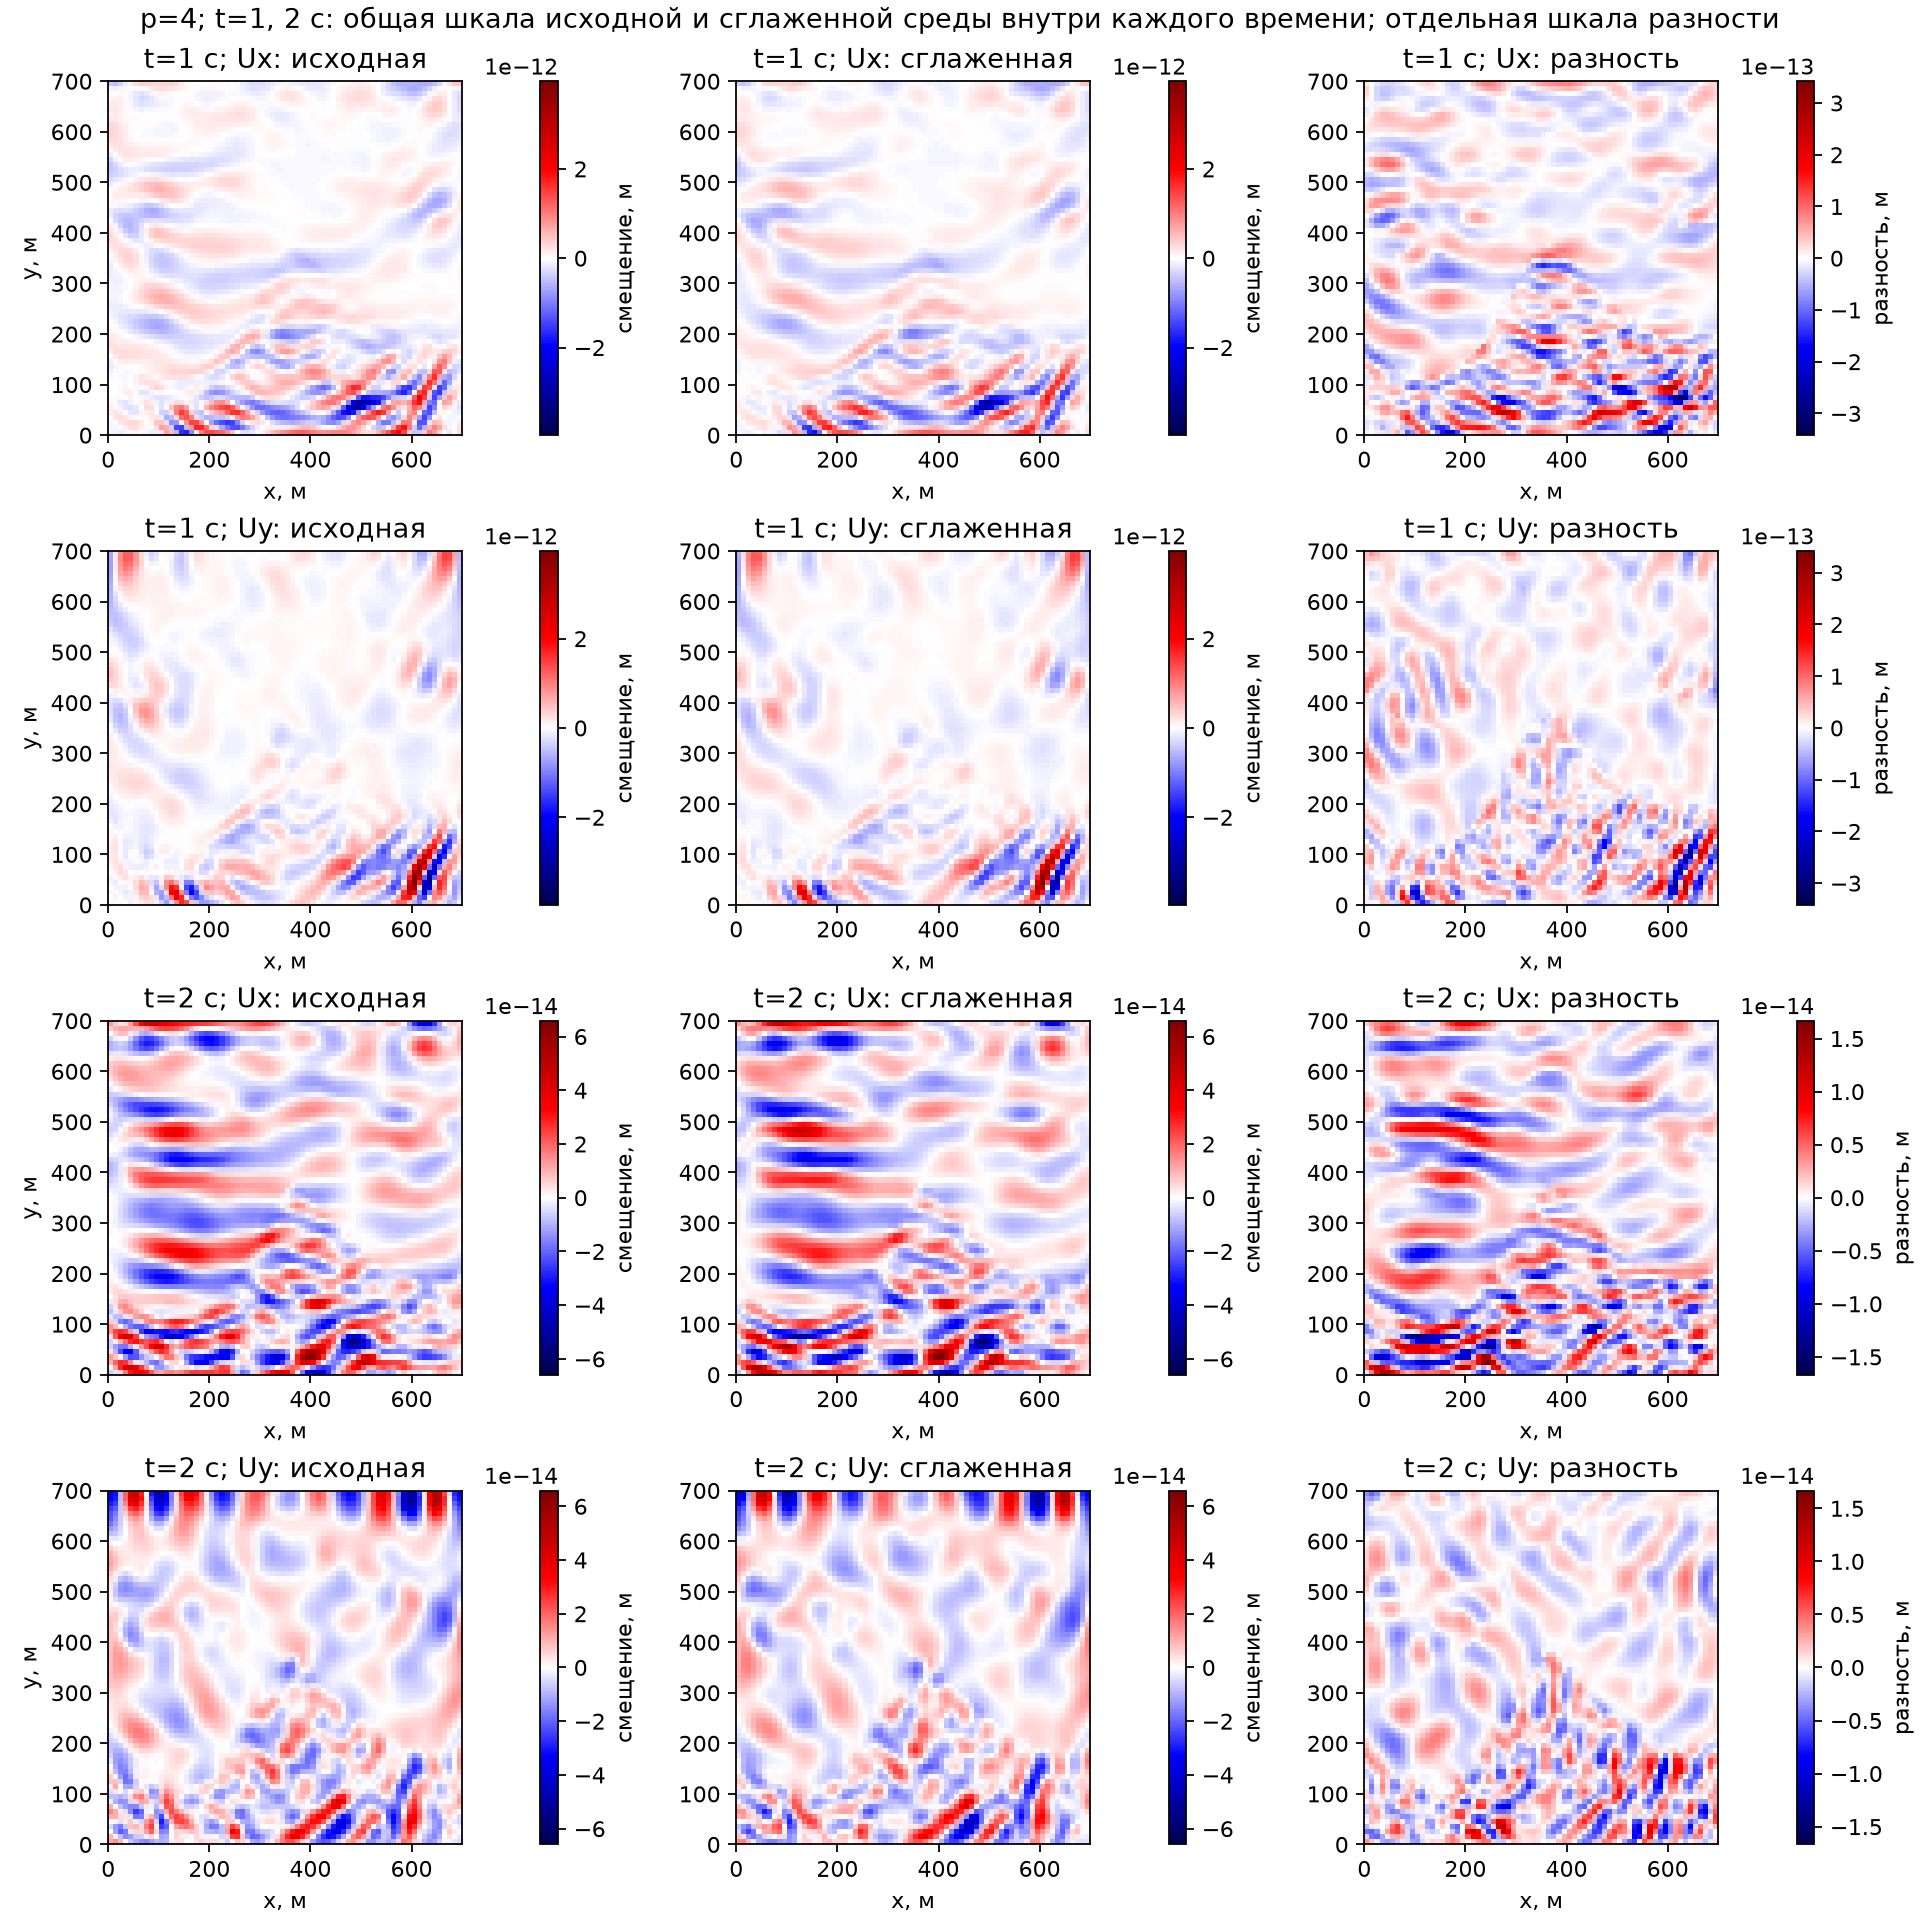

In [10]:
slide_figure(12, width=800)
slide_figure(13, width=800)

### Контроль порядка и шага по времени на ECVB12404 ###

На каждой из двух фиксированных Q2-сеток сравнивали соседние порядки при одинаковом временном шаге внутри пары. За опору брали решение старшего порядка. Отдельно при p4 вдвое уменьшили шаг по времени, взяв за опору расчёт с меньшим шагом. Таблица даёт минимум и максимум относительной разности в процентах по двум компонентам и обеим геометриям. Это исходная серия контроля на CPU.

In [11]:
metrics = mapping(read_json(data / "pilot_runs/comparison/metrics.json")["metrics"])
records = {str(record["name"]): record for record in map(mapping, sequence(metrics["records"]))}
rows = ["| Проверка | Запись 0–2 с, % | Кода 1–2 с, % | Поле при 2 с, % |", "|---|---:|---:|---:|"]
for label, transition, digits in (
    ("p2 → p3", "p2 to p3", 2),
    ("p3 → p4", "p3 to p4", 2),
    ("p4 → p5", "p4 s36 to p5 s36", 2),
    ("Δt → Δt/2 при p4", "p4 s18 to s36 temporal", 4),
):
    full_values: list[float] = []
    late_values: list[float] = []
    field_values: list[float] = []
    for geometry in ("raster", "curved"):
        record = records[f"{geometry}: {transition}"]
        surface = mapping(record["surface"])
        windows = map(mapping, sequence(surface["time_windows"]))
        late = next(window for window in windows if pair(window["time_window_s"]) == (1.0, 2.0))
        fields = map(mapping, sequence(record["fields"]))
        final = next(field for field in fields if field["time_s"] == 2.0)
        full_values.extend(pair(surface["all_surface"]))
        late_values.extend(pair(late["relative_l2"]))
        field_values.extend(pair(final["relative_l2"]))
    ranges = [f"{percent(min(values), digits)}–{percent(max(values), digits)}" for values in (full_values, late_values, field_values)]
    rows.append("| " + " | ".join([label, *ranges]) + " |")
display(Markdown("\n".join(rows)))

| Проверка | Запись 0–2 с, % | Кода 1–2 с, % | Поле при 2 с, % |
|---|---:|---:|---:|
| p2 → p3 | 3,02–4,69 | 10,98–20,54 | 13,02–36,66 |
| p3 → p4 | 0,30–0,78 | 0,37–0,76 | 0,26–1,55 |
| p4 → p5 | 0,11–0,15 | 0,08–0,12 | 0,03–0,04 |
| Δt → Δt/2 при p4 | 0,0029–0,0034 | 0,0185–0,0224 | 0,0222–0,0241 |

На растре переход p4 → p5 меняет полную запись на 0,152% по Ux и 0,106% по Uy, уменьшение шага вдвое при p4 — на 0,0034% и 0,0029%. В презентации p3 рассматривался как кандидат для массовой серии при 15 Гц. Для измерения малых различий между геометриями использованы p4 и p5.

Чтобы оценить, разрешён ли эффект сглаживания, норму разности двух решений при p5 делили на сумму норм поправок p4 → p5 для растровой и гладкой сеток. В позднем окне отношение составило 109,60 для Ux и 65,01 для Uy. Для всей записи получено лишь 2,76 и 2,40 при принятом в протоколе пороге 5. Эта проверка относится к №12404.

### Вывод ###

На обоих пилотах сглаживание гораздо сильнее меняет слабую позднюю коду, чем полную сейсмограмму. Для №12404 величина изменения коды уверенно превышает наблюдаемые поправки дискретизации. Для №00065 опыт подтвердил сохранение топологии, включая контакт в одну растровую ячейку. Здесь одновременно с границами изменились форма и число элементов, а ранняя серия содержит только пару p4 при одном шаге. Её результат характеризует чувствительность ко всей замене сетки.

Допуск на сглаживание имеет смысл задавать по интересующему волновому событию и указывать абсолютный уровень сигнала. Следующая [глава 1.3](dev_1_3_point_source.ipynb) рассматривает другую постановку с точечным источником 30 Гц. Для неё сохранён [ролик с сопоставлением скорости на четырёх сетках raster/curved × p4/p5](img/dev_1_3_point_source/central_cu_v1/animation_00065_v1/speed.mp4).